<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/04_perceptron_learning_rule.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 4: The Perceptron Learning Rule

Lesson 4 of 8, about 30 minutes.

After this lesson you should be able to:

1. Apply the perceptron rule $\Delta\mathbf{w} = c\,(d - o)\,\mathbf{x}$ by hand and in code.
2. Explain what the bias input and the learning constant do.
3. Follow a decision boundary as a perceptron learns a 2-D classification problem.
4. State the perceptron convergence theorem and see what happens when the data are not linearly separable.

You will need: lessons 1 to 3.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Learning from mistakes

Hebbian learning reinforces whatever the neuron already does. Rosenblatt's perceptron (1958) adds a
teacher that gives the desired output $d \in \{-1, +1\}$ for every input, and the neuron changes
its weights only when it gets an answer wrong:

$$
o = \operatorname{sgn}(\mathbf{w}^\top\mathbf{x}), \qquad
\Delta\mathbf{w} = c\,(d - o)\,\mathbf{x}
$$

If $o = d$, the error $d - o$ is zero and nothing changes. If the neuron says $-1$ when the answer
is $+1$, the update adds $2c\,\mathbf{x}$, which moves $\mathbf{w}$ towards $\mathbf{x}$ and raises
$\mathbf{w}^\top\mathbf{x}$ next time. The opposite mistake moves $\mathbf{w}$ away from $\mathbf{x}$.

The last component of every input below is a constant $-1$. Its weight acts as the threshold
$\theta$ from lesson 1, except that now it is learned along with the other weights. This is called
the bias.

## Worked example

From Zurada (1992): $\mathbf{w}^1 = [1,\ -1,\ 0,\ 0.5]$, $c = 0.1$ and three labelled patterns.

| pattern | $\mathbf{x}$ | $d$ |
|---|---|---|
| 1 | $[1,\ -2,\ 0,\ -1]$ | $-1$ |
| 2 | $[0,\ 1.5,\ -0.5,\ -1]$ | $-1$ |
| 3 | $[-1,\ 1,\ 0.5,\ -1]$ | $+1$ |

Step 1: $net = 1 + 2 + 0 - 0.5 = 2.5$, so $o = +1$, which is wrong. The error is $d - o = -2$, so
$\mathbf{w}^2 = \mathbf{w}^1 - 0.2\,\mathbf{x}_1 = [0.8,\ -0.6,\ 0,\ 0.7]$.

In [2]:
from nnlab.learning_rules import perceptron

w0 = [1, -1, 0, 0.5]
X = [[1, -2, 0, -1],
     [0, 1.5, -0.5, -1],
     [-1, 1, 0.5, -1]]
d = [-1, -1, 1]

one_epoch = perceptron(w0, X, d, c=0.1, epochs=1)
one_epoch.print_steps()

initial w = [ 1.  -1.   0.   0.5]
epoch 1, x1:  net = +2.500  o = +1.000  d = -1  ->  w = [ 0.8 -0.6  0.   0.7]
epoch 1, x2:  net = -1.600  o = -1.000  d = -1  ->  w = [ 0.8 -0.6  0.   0.7]
epoch 1, x3:  net = -2.100  o = -1.000  d = +1  ->  w = [ 0.6 -0.4  0.1  0.5]


After one pass through the data the neuron still gets a pattern wrong. We keep going until a whole
pass (an epoch) has no mistakes.

In [3]:
trained = perceptron(w0, X, d, c=0.1, epochs=100)
print(f"converged: {trained.converged} after {trained.n_epochs} epochs")
print("mistakes per epoch:", trained.epoch_errors)
print("final weights:", trained.weights)
print("outputs:", np.sign(np.asarray(X) @ trained.weights), " targets:", d)

converged: True after 5 epochs
mistakes per epoch: [2.0, 2.0, 1.0, 2.0, 0.0]
final weights: [-0.2  0.3  0.5  0.3]
outputs: [-1. -1.  1.]  targets: [-1, -1, 1]


## Watching the boundary move

Four-dimensional weights are hard to picture, so here is a problem in two dimensions. Each point
is $(x_1, x_2)$ with a constant 1 appended as the bias input. The boundary
$w_1 x_1 + w_2 x_2 + w_3 = 0$ is a line, and we draw it after every epoch.

In [4]:
rng = np.random.default_rng(0)
n = 25
pos = rng.normal(loc=(1.5, 1.5), scale=0.7, size=(n, 2))
neg = rng.normal(loc=(-1.0, -0.5), scale=0.7, size=(n, 2))
points = np.vstack([pos, neg])
labels = np.r_[np.ones(n), -np.ones(n)]
X2 = np.hstack([points, np.ones((2 * n, 1))])   # bias input = 1

order = rng.permutation(2 * n)                  # shuffle once
hist2d = perceptron([1.0, -2.0, 1.5], X2[order], labels[order], c=0.1, epochs=50)
print(f"converged after {hist2d.n_epochs} epochs, mistakes per epoch: {hist2d.epoch_errors}")

converged after 6 epochs, mistakes per epoch: [9.0, 3.0, 1.0, 2.0, 1.0, 0.0]


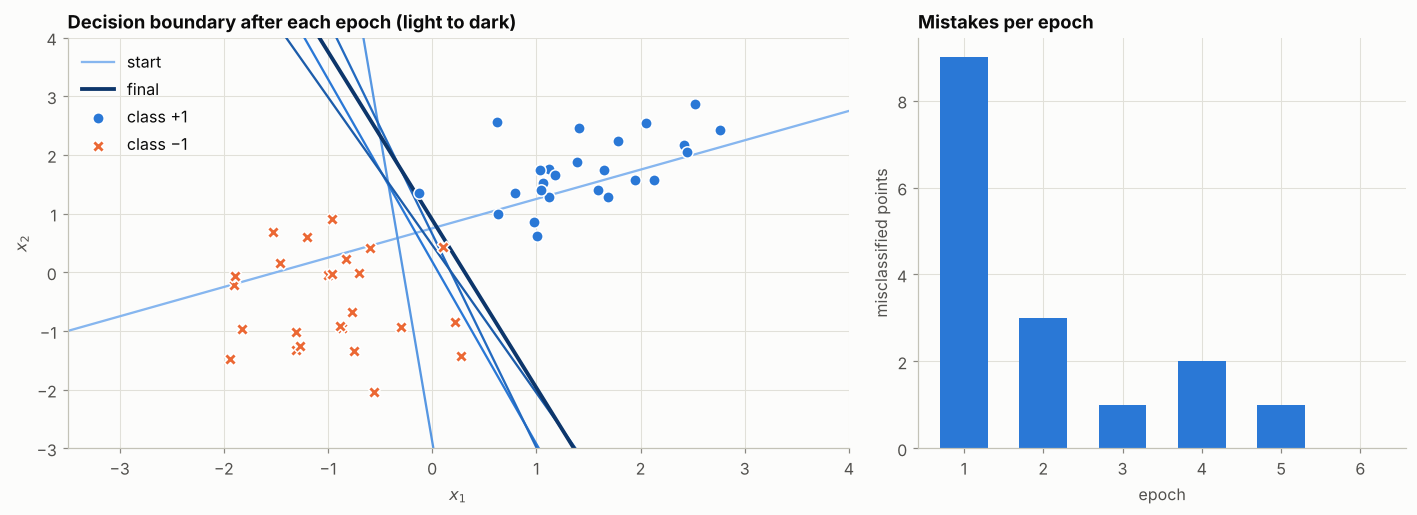

In [5]:
from matplotlib import colormaps

def boundary(ax, w, **kw):
    xs = np.array([-3.5, 4])
    if abs(w[1]) > 1e-12:
        ax.plot(xs, -(w[0] * xs + w[2]) / w[1], **kw)

# weights at the end of each epoch
per_epoch = [hist2d.initial_weights] + [
    s.weights for s in hist2d.steps if s.sample == len(order) - 1
]
shades = colormaps["nnlab_seq"](np.linspace(0.25, 1, len(per_epoch)))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
for i, (w, c) in enumerate(zip(per_epoch, shades)):
    boundary(ax, w, color=c, lw=1.5 if i < len(per_epoch) - 1 else 2.5,
             label="start" if i == 0 else ("final" if i == len(per_epoch) - 1 else None))
ax.scatter(*pos.T, marker="o", s=55, color=PALETTE[0], edgecolor="white", label="class +1", zorder=3)
ax.scatter(*neg.T, marker="X", s=65, color=PALETTE[1], edgecolor="white", label="class −1", zorder=3)
ax.set(xlim=(-3.5, 4), ylim=(-3, 4), xlabel="$x_1$", ylabel="$x_2$",
       title="Decision boundary after each epoch (light to dark)")
ax.legend(loc="upper left")

ax2.bar(range(1, len(hist2d.epoch_errors) + 1), hist2d.epoch_errors, color=PALETTE[0], width=0.6)
ax2.set(title="Mistakes per epoch", xlabel="epoch", ylabel="misclassified points")
fig.tight_layout()
plt.show()

## Convergence, and when it fails

The perceptron convergence theorem (Rosenblatt, 1958; Novikoff, 1962) says that if the two classes
can be separated by a straight line, the perceptron rule finds such a line after a finite number of
updates, for any $c > 0$.

The theorem says nothing about data that cannot be separated. Here is XOR in bipolar form:

In [6]:
X_xor = [[-1, -1, 1], [-1, 1, 1], [1, -1, 1], [1, 1, 1]]   # x1, x2, bias
d_xor = [-1, 1, 1, -1]
xor_hist = perceptron([0.1, -0.2, 0.3], X_xor, d_xor, c=0.1, epochs=40)
print("converged:", xor_hist.converged)
print("mistakes in the last 10 epochs:", xor_hist.epoch_errors[-10:])

converged: False
mistakes in the last 10 epochs: [4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0]


The weights cycle forever and there are always mistakes. This is the limitation Minsky and Papert
(1969) pointed out. Lesson 6 fixes it with a hidden layer trained by backpropagation.

## Exercises

1. Run the 2-D example again with $c = 1$ and with $c = 0.01$. Does the number of epochs change?
   Does the final boundary change? (Think about what multiplying every weight by the same positive
   number does to $\operatorname{sgn}(\mathbf{w}^\top\mathbf{x})$.)
2. Move the two clouds closer together, for example `loc=(0.3, 0.3)`, until they overlap. What
   happens to the number of mistakes per epoch?

**Answer to exercise 1**

<details><summary>Answer</summary>

If training starts from $\mathbf{w} = \mathbf{0}$, the learning constant only rescales every weight vector along the way. Since $\operatorname{sgn}(\mathbf{w}^\top\mathbf{x})$ does not change under positive scaling, every decision and the number of epochs are the same for any $c$. When training starts from non-zero weights, as it does here, $c$ controls how quickly the initial guess is overridden, so the run can differ.

</details>

## Summary

- The perceptron rule Δw = c(d − o)x only changes the weights after a mistake.
- A constant bias input lets the neuron learn its own threshold.
- On linearly separable data training is guaranteed to stop after finitely many updates.
- On data such as XOR it never settles, so one layer is not enough.

Next: [Lesson 5, The Delta Rule and Gradient Descent](05_delta_rule.ipynb)

### References

- Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408.
- Novikoff, A. B. J. (1962). On convergence proofs on perceptrons. *Proceedings of the Symposium on the Mathematical Theory of Automata*, 12, 615–622.
- Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.